In [1]:
########################################################
###################### Importierte Packete #############
########################################################

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import rc                                                   # To use a LaTeX font
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.colors import rgb2hex
from matplotlib.collections import LineCollection
from matplotlib import colors as mcolors


#import csv

import numpy as np

import pandas as pd

import scipy
from scipy import stats
import scipy.constants as sc
from scipy import ndimage
import scipy.signal
from scipy.interpolate import interp1d

import statsmodels.api as sm

from mpl_toolkits import mplot3d                                            # Um 3D Plots zu machen

import os

##### Saving/packing of data
import pickle

##### To create colour gradients
from colour import Color

In [2]:
# importing the own functions from the scientific_utils package
from scientific_utils.battery.plotting import Matplotlib_Overview_Single_Dataframe
from scientific_utils.battery.plotting import Matplotlib_Overview_With_Colormap
from scientific_utils.general.plotting import Convert_cm_To_inch

In [3]:
# create the output folder if it does not exist yet
if not os.path.exists('./images/'):
    os.mkdir('./images/')

In [4]:
#########################################################
##################### Start of the code ##################
#########################################################

In [5]:
########## Open the saved lists from the .pkl files ########

########## Open the OCV steps before the CP step
##### OCVs before a Charging step in the C Rate Test
#with open('../data/Batt15/processed/list_of_dataframes_of_OCV_before_CP_step_charge.pkl', 'rb') as f:
#    list_of_dataframes_of_OCV_before_CP_step_charge = pickle.load(f)

##### OCVs before a Discharging step in the C Rate Test
#with open('../data/Batt15/processed/list_of_dataframes_of_OCV_before_CP_step_discharge.pkl', 'rb') as f:
#    list_of_dataframes_of_OCV_before_CP_step_discharge = pickle.load(f)  

    
########## save the CP steps
##### CP charge steps
with open('../data/Batt15/processed/list_of_dataframes_of_CP_charge.pkl', 'rb') as f:
    list_of_dataframes_of_CP_charge = pickle.load(f)    

##### CP discharge steps
with open('../data/Batt15/processed/list_of_dataframes_of_CP_discharge.pkl', 'rb') as f:
    list_of_dataframes_of_CP_discharge = pickle.load(f) 

    
########## save the OCV steps after the CP step
##### OCVs after a Charging step in the C Rate Test
with open('../data/Batt15/processed/list_of_dataframes_of_OCV_after_CP_step_charge.pkl', 'rb') as f:
    list_of_dataframes_of_OCV_after_CP_step_charge = pickle.load(f) 

##### OCVs after a Discharging step in the C Rate Test
with open('../data/Batt15/processed/list_of_dataframes_of_OCV_after_CP_step_discharge.pkl', 'rb') as f:
    list_of_dataframes_of_OCV_after_CP_step_discharge = pickle.load(f) 


########## Create a list with more information about the data for plotting later #######
list_RateTest_labels = ['0.10 C Rate', '0.33 C Rate', '0.50 C Rate', '1.00 C Rate', '2.00 C Rate']


In [6]:
########## Define colours by hex code ##########
yellow = '#ffa200'
orange = '#f97625'
lightpink = '#e94a3a'
pink = '#ce1b49'
lightpurple = '#a90054'
purple = '#7e0059'
darkpurple = '#4c0057'
darkblue = '#0a004d'

########## Colours in a list to access them in a for loop ##########
colors = [yellow, orange, lightpink, pink, lightpurple, purple, darkpurple, darkblue]


########## Colour gradient with the colour package
#beginnig_color = Color("yellow")
#end_color = Color("blue")
#number_of_colorpoints = 4
#color_gradient = list(beginnig_color.range_to(end_color,number_of_colorpoints))
#print(color_gradient)


########## Cologradient with Matplotlib Colormaps
# Available colormaps: https://matplotlib.org/3.1.0/tutorials/colors/colormaps.html#ibm
number_of_colorpoints = 3 # number of colour points taken from the colour gradient with equal distance
colormap = plt.get_cmap('coolwarm', number_of_colorpoints) # Loads a ready-made colormap from Matplotlib
array_of_RGBAcolors = colormap(range(number_of_colorpoints)) # Returns the colormap as RGBA values scaled from 0 to 1
list_of_Hexcolors = [ rgb2hex(array_of_RGBAcolors[i,:]) for i in range(array_of_RGBAcolors.shape[0]) ] # Converts the scaled RGBA values to hex code and puts them in a list


In [7]:
########## Font settings for the PGF file ##########
pgf_with_latex = {                      # setup matplotlib to use latex for output
    "pgf.texsystem": "xelatex",         # change this if using xetex or lautex
    "text.usetex": False,                # use LaTeX to write all text
    #"pgf.rcfonts": False,               # don't setup fonts from rc parameters
    "font.family": "sans-serif",           # standard sans-serif font of Matplotlib
    #"mathtext.fontset": "stixsans",
    "legend.title_fontsize" : 14,
    "legend.fontsize": 10,              # Make the legend/label fonts a little smaller
    "axes.labelsize": 12,               # LaTeX default is 10pt font.
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize" : Convert_cm_To_inch(16, 8),
    'savefig.dpi'         : 300,   ## figure dots per inch or 'figure'
    'savefig.facecolor'   : 'white',    ## figure facecolor when saving
    'savefig.edgecolor'   : 'white',    ## figure edgecolor when saving
    'savefig.format'      : 'png',      ## png, ps, pdf, svg
    'savefig.bbox'        : 'tight', 
    "pgf.preamble": "\n".join([
        r"\usepackage[T1]{fontenc}",    # use utf8 fonts becasue your computer can handle it :)
        r"\usepackage{fontspec}",        # plots will be generated using this preamble
        r"\usepackage{fourier}",
        r"\usepackage{unicode-math}",
        r"\usepackage[basic,italic,symbolgreek,numbers]{mathastext}"
        ])
    }

plt.rcParams.update(pgf_with_latex)

##### one style for all plots: the shared publication style (scientific_utils.general.plotting) replaces the local settings above
from scientific_utils.general.plotting import pgf_with_latex
plt.rcParams.update(pgf_with_latex)

In [8]:
################### Plotting of the charging functions ####################

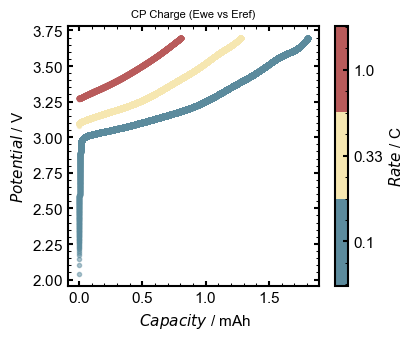

In [9]:
# Plotting of the Charging curves with the above definened function

list_of_dataframes = list_of_dataframes_of_CP_charge
x_values_column_name = 'Q charge/mA.h'
y_values_column_name = '<Ewe>/V'
y_ax_label = r' $ Potential $ / V  '
x_ax_label = r' $ Capacity $ / mAh '
save = 1
name_figure = 'CP_Charge_Ewe_vs_Eref'
legend_title = 'CP Charge (Ewe vs Eref)'

Matplotlib_Overview_With_Colormap(list_of_dataframes, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, save, name_figure, legend_title, list_of_labels=list_RateTest_labels)

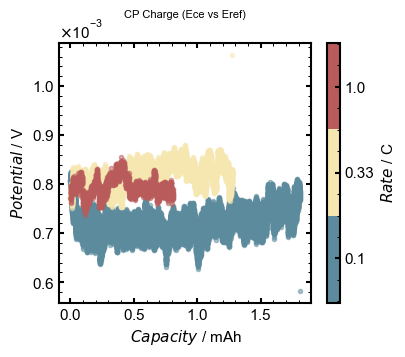

In [10]:
# Plotting of the Charging curves with the above definened function

list_of_dataframes = list_of_dataframes_of_CP_charge
x_values_column_name = 'Q charge/mA.h'
y_values_column_name = '<Ece>/V'
y_ax_label = r' $ Potential $ / V  '
x_ax_label = r' $ Capacity $ / mAh '
save = -1 
name_figure = 'CP_Charge_Ece_vs_Eref'
legend_title = 'CP Charge (Ece vs Eref)'

Matplotlib_Overview_With_Colormap(list_of_dataframes, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, save, name_figure, legend_title, list_of_labels=list_RateTest_labels)

In [11]:
################### Plotting of the discharging functions ####################

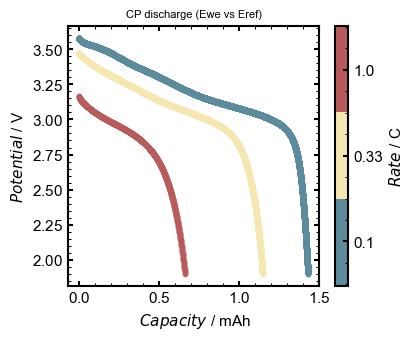

In [12]:
# Plotting of the Charging curves with the above definened function

list_of_dataframes = list_of_dataframes_of_CP_discharge
x_values_column_name = 'Q discharge/mA.h'
y_values_column_name = '<Ewe>/V'
y_ax_label = r' $ Potential $ / V  '
x_ax_label = r' $ Capacity $ / mAh '
save = 1 
name_figure = 'CP_discharge_Ewe_vs_Eref'
legend_title = 'CP discharge (Ewe vs Eref)'

Matplotlib_Overview_With_Colormap(list_of_dataframes, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, save, name_figure, legend_title, list_of_labels=list_RateTest_labels)

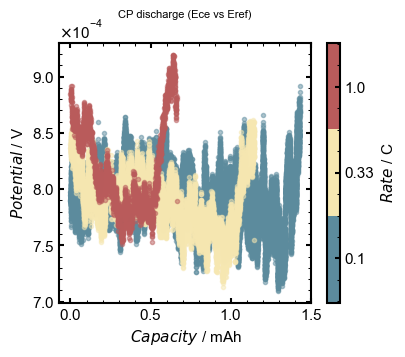

In [13]:
# Plotting of the Charging curves with the above definened function

list_of_dataframes = list_of_dataframes_of_CP_discharge
x_values_column_name = 'Q discharge/mA.h'
y_values_column_name = '<Ece>/V'
y_ax_label = r' $ Potential $ / V  '
x_ax_label = r' $ Capacity $ / mAh '
save = -1
name_figure = 'CP_discharge_Ece_vs_Eref'
legend_title = 'CP discharge (Ece vs Eref)'

Matplotlib_Overview_With_Colormap(list_of_dataframes, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, save, name_figure, legend_title, list_of_labels=list_RateTest_labels)

In [14]:
################### Plotting of the OCV after charging ####################

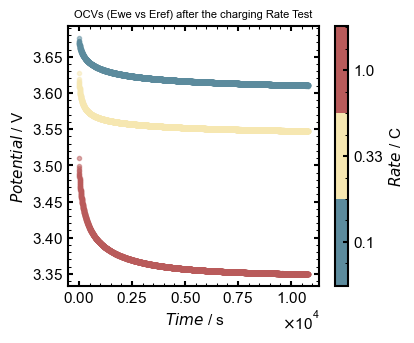

In [15]:
# Plotting of the Charging curves with the above definened function

list_of_dataframes = list_of_dataframes_of_OCV_after_CP_step_charge
x_values_column_name = 'time/s'
y_values_column_name = 'Ewe/V'
y_ax_label = r' $ Potential $ / V  '
x_ax_label = r' $ Time $ / s '
save = 1 
name_figure = 'OCVs_Ewe_vs_Eref_after_the_charging_Rate_Test'
legend_title = 'OCVs (Ewe vs Eref) after the charging Rate Test'

Matplotlib_Overview_With_Colormap(list_of_dataframes, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, save, name_figure, legend_title, list_of_labels=list_RateTest_labels)

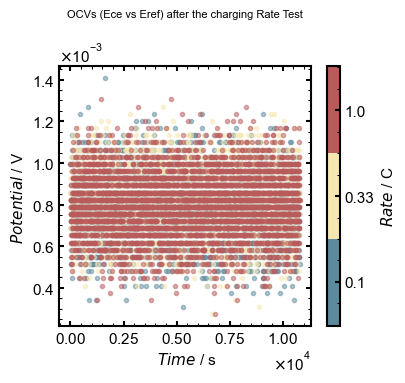

In [16]:
# Plotting of the Charging curves with the above definened function

list_of_dataframes = list_of_dataframes_of_OCV_after_CP_step_charge
x_values_column_name = 'time/s'
y_values_column_name = 'Ece/V'
y_ax_label = r' $ Potential $ / V  '
x_ax_label = r' $ Time $ / s '
save = -1
name_figure = 'OCVs_Ece_vs_Eref_after_the_charging_Rate_Test'
legend_title = 'OCVs (Ece vs Eref) after the charging Rate Test'

Matplotlib_Overview_With_Colormap(list_of_dataframes, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, save, name_figure, legend_title, list_of_labels=list_RateTest_labels)

In [17]:
################### Plotting of the CP and OCV vs time ####################

In [18]:

display(list_of_dataframes_of_CP_charge[0])
display(list_of_dataframes_of_OCV_after_CP_step_charge[0])

,mode,ox/red,error,control changes,Ns changes,counter inc.,Ns,time/s,control/mA,<Ewe>/V,...,Capacitance charge/µF,Capacitance discharge/µF,Q discharge/mA.h,Q charge/mA.h,Capacity/mA.h,Efficiency/%,cycle number,P/W,Ewe-Ece/V,Unnamed: 29
0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.500000,0.1848,2.040372,...,0.000000e+00,0.0,0.0,0.000023,0.000023,0.0,0.0,0.000377,2.039566,NaN
1,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.000000,0.1848,2.101882,...,2.851018e+03,0.0,0.0,0.000049,0.000049,0.0,0.0,0.000388,2.101082,NaN
2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.500000,0.1848,2.142325,...,2.626687e+03,0.0,0.0,0.000074,0.000074,0.0,0.0,0.000396,2.141517,NaN
3,1.0,1.0,0.0,0.0,0.0,0.0,0.0,2.000000,0.1848,2.169337,...,2.793319e+03,0.0,0.0,0.000100,0.000100,0.0,0.0,0.000401,2.168531,NaN
4,1.0,1.0,0.0,0.0,0.0,0.0,0.0,2.500000,0.1848,2.188307,...,3.060021e+03,0.0,0.0,0.000126,0.000126,0.0,0.0,0.000405,2.187500,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70388,1.0,1.0,0.0,0.0,0.0,0.0,0.0,35194.499554,0.1848,3.699703,...,3.922334e+06,0.0,0.0,1.807903,1.807903,0.0,0.0,0.000684,3.698929,NaN
70389,1.0,1.0,0.0,0.0,0.0,0.0,0.0,35194.999554,0.1848,3.699738,...,3.922307e+06,0.0,0.0,1.807928,1.807928,0.0,0.0,0.000684,3.698968,NaN
70390,1.0,1.0,0.0,0.0,0.0,0.0,0.0,35195.499554,0.1848,3.699778,...,3.922269e+06,0.0,0.0,1.807954,1.807954,0.0,0.0,0.000684,3.699007,NaN
70391,1.0,1.0,0.0,0.0,0.0,0.0,0.0,35195.813154,0.1848,3.699799,...,3.922254e+06,0.0,0.0,1.807970,1.807970,0.0,0.0,0.000685,3.699028,NaN


,mode,error,time/s,Ewe/V,Ece/V,Analog IN 1/V,Ewe-Ece/V,Unnamed: 7
0,3.0,0.0,35195.863554,3.675942,0.000995,0.000056,3.674946,NaN
1,3.0,0.0,35198.363554,3.672458,0.000755,0.000118,3.671703,NaN
2,3.0,0.0,35200.863554,3.671194,0.000858,0.000118,3.670336,NaN
3,3.0,0.0,35203.363554,3.670227,0.000583,0.000072,3.669645,NaN
4,3.0,0.0,35205.863554,3.669567,0.000755,0.000072,3.668812,NaN
...,...,...,...,...,...,...,...,...
4316,3.0,0.0,45985.863574,3.610357,0.000548,0.000003,3.609809,NaN
4317,3.0,0.0,45988.363574,3.610433,0.000755,0.000087,3.609679,NaN
4318,3.0,0.0,45990.863574,3.610391,0.000617,0.000072,3.609774,NaN
4319,3.0,0.0,45993.363574,3.610349,0.000789,0.000064,3.609561,NaN


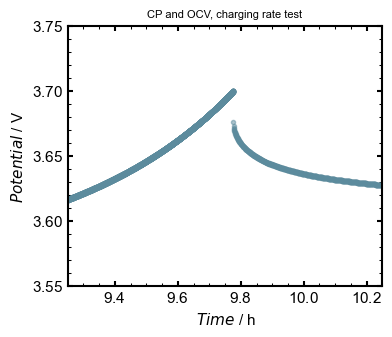

In [19]:
dataframes_CP_vs_time = pd.DataFrame()
dataframes_CP_vs_time['time/s'] = list_of_dataframes_of_CP_charge[0]['time/s'] - list_of_dataframes_of_CP_charge[0].iloc[0]['time/s']
dataframes_CP_vs_time['Ewe/V'] = list_of_dataframes_of_CP_charge[0]['<Ewe>/V']

dataframes_OCV_vs_time = pd.DataFrame()
dataframes_OCV_vs_time['time/s'] = (list_of_dataframes_of_OCV_after_CP_step_charge[0]['time/s'] - list_of_dataframes_of_OCV_after_CP_step_charge[0].iloc[0]['time/s']) + dataframes_CP_vs_time.iloc[-1]['time/s'] 
dataframes_OCV_vs_time['Ewe/V'] = list_of_dataframes_of_OCV_after_CP_step_charge[0]['Ewe/V']

dataframes_CP_OCV_vs_time = pd.concat([dataframes_CP_vs_time, dataframes_OCV_vs_time], ignore_index=True)
dataframes_CP_OCV_vs_time['time/h'] = dataframes_CP_OCV_vs_time['time/s']/60/60

#display(dataframes_CP_OCV_vs_time)

list_of_dataframes = dataframes_CP_OCV_vs_time
x_values_column_name = 'time/h'
y_values_column_name = 'Ewe/V'
y_ax_label = r' $ Potential $ / V  '
x_ax_label = r' $ Time $ / h '
save = 1
name_figure = 'CP_and_OCV_for_charging_Rate_Test_zoomed'
legend_title = 'CP and OCV, charging rate test'

Matplotlib_Overview_Single_Dataframe(list_of_dataframes, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, save, name_figure, legend_title)

In [20]:
################### Plotting of the OCV after discharging ####################

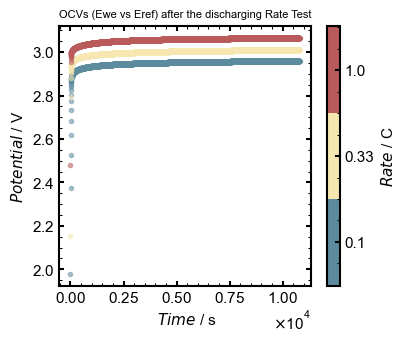

In [21]:
# Plotting of the Charging curves with the above definened function

list_of_dataframes = list_of_dataframes_of_OCV_after_CP_step_discharge
x_values_column_name = 'time/s'
y_values_column_name = 'Ewe/V'
y_ax_label = r' $ Potential $ / V  '
x_ax_label = r' $ Time $ / s '
save = 1 
name_figure = 'OCVs_Ewe_vs_Eref_after_the_discharging_Rate_Test'
legend_title = 'OCVs (Ewe vs Eref) after the discharging Rate Test'

Matplotlib_Overview_With_Colormap(list_of_dataframes, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, save, name_figure, legend_title, list_of_labels=list_RateTest_labels)

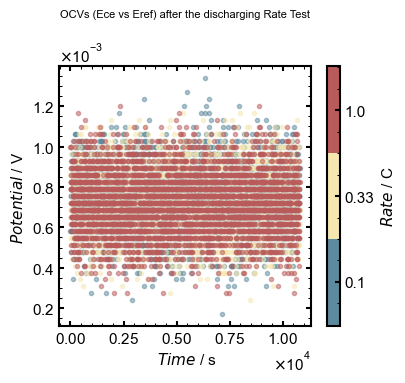

In [22]:
# Plotting of the Charging curves with the above definened function

list_of_dataframes = list_of_dataframes_of_OCV_after_CP_step_discharge
x_values_column_name = 'time/s'
y_values_column_name = 'Ece/V'
y_ax_label = r' $ Potential $ / V  '
x_ax_label = r' $ Time $ / s '
save = -1
name_figure = 'OCVs_Ece_vs_Eref_after_the_discharging_Rate_Test'
legend_title = 'OCVs (Ece vs Eref) after the discharging Rate Test'

Matplotlib_Overview_With_Colormap(list_of_dataframes, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, save, name_figure, legend_title, list_of_labels=list_RateTest_labels)